# 20 v4 · Skin: priced false referrals, two bounds, operating characteristics, case influence, CNN against transformer (secondary, post hoc)

**v4 (29 Oct 2026).** Same seed and code as v3, so every v3 number reproduces. In the union (section 6) the better member for the per-death rows is now chosen on expected deaths, the outcome each row reports, as in sections 4 and 5; v3 chose it on melanoma for every row, and that definition is still reported alongside. v3 added bootstrap intervals for the union costs and the sources for the reference band.

**Status: secondary and post hoc.** No dated lock specified these analyses. They mirror notebooks 18, 18b and 19 (retina) for the two skin test sets, HIBA and PAD-UFES-20. The notebook reads only frozen prediction files and changes no locked result. Every result is reported whatever it shows.

**Systems and pairs.** There are 24 skin systems: 2 training collections (HAM10000, BCN20000) × 6 designs × 2 seeds. A pair is any two of the 12 collection-design variants, 66 pairs × 4 seed combinations = 264 combinations, the skin analogue of the 55 retina pairs × 9 seeds. Siblings (two seeds of one variant) are not pairs here. The referral rule is the one used throughout: top f by within-population rank, the pair taking the higher of its two ranks. f = 1.31 × malignant prevalence, as in the confirmatory skin analysis.

**Harm per missed lesion.**

| Missed lesion | Average case: deaths per miss | Worst case | Source |
|---|---|---|---|
| Melanoma | 1/85 (range 1/120 to 1/50) | 1 (every missed melanoma is a melanoma death) | Gilmore 2017, PLoS ONE: 50 to 120 early invasive melanoma excisions per life saved (Australia, 1982 to 2013) |
| SCC | 0.006 | 0.006 | Tokez et al. 2022, JAAD: 5-year SCC-specific mortality about 0.6% (Dutch national cohort, 11,137 patients); generous for a delay |
| BCC | 0 | 0 | |

The worst case is an extreme bound, as the retina "every missed severe eye blinds" bound is. It is stated as one: 10-year melanoma-specific survival for stage IA is about 98%. A screener cannot tell at the point of a miss which melanoma is indolent, which is why the bound is the clinically relevant one.

**The two bounds**, as in retina:

| Bound | Comparator | Harm |
|---|---|---|
| Mathematically conservative | Better system of each pair (with hindsight) | Average case |
| Clinically conservative | Deployed system (average of the two) | Worst case |

All four combinations are also reported.

**Pricing.** A false referral (a benign lesion referred) costs 1/K of one melanoma death. K is swept from 1 to 100,000. The **break-even K** is the smallest K above which the tuned pair stays ahead of the tuned comparator. Reference band: clinicians already accept about 5 to 30 biopsies per melanoma found. Pooled number needed to biopsy runs from 5.9 for pigmented-lesion specialists through 9.6 in dermatology to 22.6 in primary care (Petty et al. 2020, JAAD, 29 studies); across individual studies it ranges from 2.2 to 30.5 (Nelson et al. 2019, JAMA Dermatology, 46 studies). Combined with 50 to 120 melanomas per death averted, that is about 250 to 3,600 benign referrals per melanoma death averted. The figure shades this band.

**Caveat.** HIBA and PAD-UFES-20 are curated, cancer-enriched sets (malignant prevalence near 46%). A break-even K here is a ratio for comparison, not a screening-programme estimate.

**Also, as notebook 19 did for retina:**
- operating characteristics of single systems and pairs;
- case influence on the HIBA melanoma result against the deployed system;
- CNN against transformer:
  - CNNs: ResNet50, DenseNet121, EfficientNet-B3, ConvNeXt-T;
  - transformers: ViT-B, DINOv2 ViT-B;
  - shown for all pairs and for pairs trained on different collections only.

**Uncertainty.** 1,000 bootstrap resamples of patients (seed 20261029), each model's rank transform fixed at the full sample, as in notebooks 18 and 18b.

CPU, High-RAM, about 30 to 60 minutes. Only aggregate numbers are written.

In [1]:
# --- setup ---
from google.colab import drive
drive.mount("/content/drive")
import os, json, hashlib, itertools, datetime, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import rankdata
DERM = "/content/drive/MyDrive/stochastic_orthogonality/data/derm"
OUTD = f"{DERM}/secondary_v4"; os.makedirs(OUTD, exist_ok=True)
OUT_JSON = f"{OUTD}/derm_secondary_v4.json"
assert not os.path.exists(OUT_JSON), "this secondary analysis has already been written; rename the old output deliberately to rerun"
SOURCES = ["HAM10000", "BCN20000"]; ARCHS = ["resnet50", "densenet121", "efficientnet_b3", "convnext_t", "vit_b", "vit_b_dinov2"]; SEEDS = [0, 1]
VARIANTS = [(s, a) for s in SOURCES for a in ARCHS]; PAIRS = list(itertools.combinations(VARIANTS, 2))
MODELS = [(s, a, k) for s, a in VARIANTS for k in SEEDS]
KIND = {a: ("transformer" if a.startswith("vit") else "CNN") for a in ARCHS}
FAMILY = {a: ("vit_b" if a.startswith("vit") else a) for a in ARCHS}
B, SEED = 1000, 20261029
VOLS = np.round(np.arange(0.01, 0.991, 0.01), 2)
KS = np.round(np.geomspace(1, 100000, 51), 2)
MEL = {"low": 1 / 120, "central": 1 / 85, "high": 1 / 50}; SCC_DEATH = 0.006
NNB_BAND = (5 * 50, 30 * 120)          # benign referrals already accepted per melanoma death averted (NNB 5 to 30 x 50 to 120 melanomas per death)
HARMS = {"lit_central": "average case (central)", "lit_low": "average case (low)", "lit_high": "average case (high)", "worst": "worst case: every missed melanoma is a death"}
CMP = ("better", "deployed")
def sha256_file(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()
print(f"{len(MODELS)} systems, {len(PAIRS)} pairs x {len(SEEDS) ** 2} seed combinations = {len(PAIRS) * len(SEEDS) ** 2}")

Mounted at /content/drive
24 systems, 66 pairs x 4 seed combinations = 264


## 1. Load HIBA and PAD-UFES-20 (frozen predictions; deduplication as in the confirmatory analysis)

In [2]:
CLASSES8 = ["MEL", "BCC", "SCC", "AK", "NV", "BKL", "DF", "VASC"]; HASHES = {}; POP = {}
for es in ("HIBA", "PAD"):
    D = pd.read_csv(f"{DERM}/manifest_{es}.csv", dtype={"image_id": str, "patient_id": str}).sort_values("image_id")
    D = D[~D.duplicated("raw_sha256", keep="first") & D.dx.isin(CLASSES8)].reset_index(drop=True); ids = D.image_id.to_numpy()
    P = {}
    for s, a, k in MODELS:
        fn = f"{DERM}/predictions/{es}__{s}_{a}_seed{k}.csv"; HASHES[os.path.basename(fn)] = sha256_file(fn)
        x = pd.read_csv(fn, dtype={"image_id": str}).drop_duplicates("image_id").set_index("image_id")["p_malignant"].astype(float).reindex(ids)
        assert x.notna().all(), fn; P[(s, a, k)] = x.to_numpy()
    dx = D.dx.to_numpy(); mal = np.isin(dx, ["MEL", "BCC", "SCC"])
    POP[es] = {"dx": dx, "group": D.patient_id.astype(str).fillna("none").to_numpy(), "P": P, "f": round(1.31 * float(mal.mean()), 4)}
    print(f"{es}: {len(dx):,} lesions | {len(set(POP[es]['group'])):,} patients | malignant {mal.mean():.3f} | melanoma {(dx == 'MEL').sum()} | SCC {(dx == 'SCC').sum()} | BCC {(dx == 'BCC').sum()} | f = {POP[es]['f']}")
print("expected f from the manuscript: HIBA about 0.61, PAD-UFES-20 about 0.62")

HIBA: 1,616 lesions | 623 patients | malignant 0.465 | melanoma 253 | SCC 158 | BCC 340 | f = 0.6088
PAD: 2,283 lesions | 1,373 patients | malignant 0.473 | melanoma 52 | SCC 190 | BCC 839 | f = 0.6203
expected f from the manuscript: HIBA about 0.61, PAD-UFES-20 about 0.62


## 2. Core computation
As in notebooks 18 and 18b: each resample is a vector of patient weights, so a resample changes cumulative sums along a fixed order and never re-sorts.

In [3]:
def setup(d):
    dx = d["dx"]; n = len(dx); codes = pd.factorize(d["group"])[0]; G = codes.max() + 1
    rng = np.random.default_rng(SEED); W = np.empty((B + 1, n), np.float32); W[0] = 1.0
    for b in range(1, B + 1): W[b] = np.bincount(rng.integers(0, G, G), minlength=G)[codes]
    mel, scc = (dx == "MEL").astype(float), (dx == "SCC").astype(float)
    contrib = {"melanoma_count": mel, "malignant_count": np.isin(dx, ["MEL", "BCC", "SCC"]).astype(float), "fp": (~np.isin(dx, ["MEL", "BCC", "SCC"])).astype(float),
               "worst": mel + SCC_DEATH * scc}
    for sc, r in MEL.items(): contrib[f"lit_{sc}"] = r * mel + SCC_DEATH * scc
    R = {m: rankdata(p) / n for m, p in d["P"].items()}
    return {"n": n, "W": W, "Wtot": W.sum(1, dtype=np.float64), "contrib": contrib, "R": R}
def curves(S, score, vols):
    o = np.argsort(-score, kind="stable"); Wo = S["W"][:, o]; cw = np.cumsum(Wo, 1, dtype=np.float64)
    pos = np.empty((B + 1, len(vols)), np.int64)
    for b in range(B + 1): pos[b] = np.searchsorted(cw[b], vols * S["Wtot"][b], side="right")
    out = {}
    for k, c in S["contrib"].items():
        cc = np.cumsum(Wo * c[o].astype(np.float32), 1, dtype=np.float64); cc = np.concatenate([np.zeros((B + 1, 1)), cc], 1)
        got = np.take_along_axis(cc, pos, 1); tot = cc[:, -1:]
        out[k] = got if k == "fp" else tot - got
    return out
def per10k(x, S): return x / S["Wtot"][:, None] * 1e4 if x.ndim == 2 else x / S["Wtot"] * 1e4
def comb(x, y, how): return np.minimum(x, y) if how == "better" else 0.5 * (x + y)
def pscore(S, ma, mb): ra, rb = S["R"][ma], S["R"][mb]; return np.maximum(ra, rb) + 1e-9 * np.minimum(ra, rb)
print("ready")

ready


## 3. Run: priced false referrals and the union
For each pair and resample this computes the pair's cost and both comparators' costs, at matched volume f and tuned across K. It also computes the union of the two members' own top-f sets.

In [4]:
RES = {}
for name, d in POP.items():
    t0 = time.time(); S = setup(d); f = d["f"]; vols = np.unique(np.r_[VOLS, f]); iF = int(np.where(vols == f)[0][0])
    SING = {m: curves(S, S["R"][m], vols) for m in MODELS}
    def tuned_k(cv): return {h: np.stack([per10k(cv[h] + cv["fp"] / K, S).min(1) for K in KS], 1) for h in HARMS}
    TK = {m: tuned_k(SING[m]) for m in MODELS}
    own = {m: S["R"][m] >= np.quantile(S["R"][m], 1 - f) for m in MODELS}
    W = S["W"]; cb = S["contrib"]
    def miss(ref, h): return (W * (~ref * cb[h])).sum(1)
    def fps(ref): return (W * (ref * cb["fp"])).sum(1)
    acc = {c: {"matched": {h: [] for h in list(HARMS) + ["melanoma_count", "malignant_count"]}, "tuned_k": {h: [] for h in HARMS},
               "union_mel": [], "union_fp": [], "union_lit": [], "union_worst": [], "union_lit_own": [], "union_fp_lit_own": [], "union_worst_own": [], "union_fp_worst_own": []} for c in CMP}
    print(f"{name}: singles done ({time.time() - t0:.0f}s)")
    for va, vb in PAIRS:
        for i in SEEDS:
            for j in SEEDS:
                ma, mb = (*va, i), (*vb, j); cvp = curves(S, pscore(S, ma, mb), vols); tkp = tuned_k(cvp); u = own[ma] | own[mb]
                mel_a, mel_b = miss(own[ma], "melanoma_count"), miss(own[mb], "melanoma_count"); better_a = mel_a <= mel_b
                for c in CMP:
                    A_ = acc[c]
                    for h in A_["matched"]: A_["matched"][h].append(per10k(comb(SING[ma][h][:, iF], SING[mb][h][:, iF], c) - cvp[h][:, iF], S))
                    for h in HARMS: A_["tuned_k"][h].append(comb(TK[ma][h], TK[mb][h], c) - tkp[h])
                    pick_ = (lambda xa, xb: np.where(better_a, xa, xb)) if c == "better" else (lambda xa, xb: 0.5 * (xa + xb))
                    A_["union_mel"].append(per10k(pick_(mel_a, mel_b) - miss(u, "melanoma_count"), S))
                    A_["union_fp"].append(per10k(fps(u) - pick_(fps(own[ma]), fps(own[mb])), S))
                    A_["union_lit"].append(per10k(pick_(miss(own[ma], "lit_central"), miss(own[mb], "lit_central")) - miss(u, "lit_central"), S))
                    A_["union_worst"].append(per10k(pick_(miss(own[ma], "worst"), miss(own[mb], "worst")) - miss(u, "worst"), S))
                    for h_ in ("lit_central", "worst"):
                        ha, hb = miss(own[ma], h_), miss(own[mb], h_); bh = ha <= hb
                        pk = (lambda xa, xb: np.where(bh, xa, xb)) if c == "better" else (lambda xa, xb: 0.5 * (xa + xb))
                        A_[f"union_{'lit' if h_ == 'lit_central' else 'worst'}_own"].append(per10k(pk(ha, hb) - miss(u, h_), S))
                        A_[f"union_fp_{'lit' if h_ == 'lit_central' else 'worst'}_own"].append(per10k(fps(u) - pk(fps(own[ma]), fps(own[mb])), S))
    m_ = lambda L: np.mean(np.stack(L), 0)
    def red(x): return {k: red(v) for k, v in x.items()} if isinstance(x, dict) else m_(x)
    RES[name] = {"f": f, "n": S["n"], "patients": int(len(set(d["group"]))), **{c: red(acc[c]) for c in CMP}}
    del SING, TK, acc
    print(f"{name}: pairs done ({time.time() - t0:.0f}s)")

HIBA: singles done (8s)
HIBA: pairs done (140s)
PAD: singles done (10s)
PAD: pairs done (188s)


## 4. A. Matched volume (per 10,000 lesions)
Pair minus comparator at f. Count rows are lesions; harm rows are melanoma-death equivalents.

In [5]:
def ci(x): return float(x[0]), float(np.percentile(x[1:], 2.5)), float(np.percentile(x[1:], 97.5))
pd.set_option("display.width", 220, "display.max_rows", 200)
LAB = {"melanoma_count": "missed melanomas (count)", "malignant_count": "missed cancers (count)", **HARMS}
rows = []
for name, r in RES.items():
    for c in CMP:
        for h, lab in LAB.items():
            p, lo, hi = ci(r[c]["matched"][h]); rows.append({"population": name, "comparator": c, "harm": lab, "advantage_per_10k": p, "ci_lo": lo, "ci_hi": hi})
A = pd.DataFrame(rows); A.to_csv(f"{OUTD}/derm_A_matched_volume_v4.csv", index=False)
A["cell"] = A.apply(lambda x: f"{x.advantage_per_10k:+.3f} ({x.ci_lo:+.3f} to {x.ci_hi:+.3f})", axis=1)
display(A.pivot_table(index="harm", columns=["population", "comparator"], values="cell", aggfunc="first"))

population                                                           HIBA                                                        PAD                                
comparator                                                         better                      deployed                       better                        deployed
harm                                                                                                                                                                
average case (central)                          +0.019 (-0.202 to +0.150)     +0.294 (+0.169 to +0.481)    -0.039 (-0.212 to +0.025)       +0.088 (-0.018 to +0.176)
average case (high)                             -0.028 (-0.376 to +0.201)     +0.414 (+0.212 to +0.734)    -0.039 (-0.288 to +0.036)       +0.129 (-0.022 to +0.259)
average case (low)                              +0.035 (-0.138 to +0.126)     +0.245 (+0.140 to +0.385)    -0.058 (-0.209 to +0.001)       +0.070 (-0.023 to +0.148)
missed cancers (count)                        +26.440 (+2.479 to +41.596)  +73.671 (+56.486 to +95.457)  +21.752 (-7.067 to +40.161)  +103.117 (+83.538 to +121.742)
missed melanomas (count)                       -6.985 (-24.423 to +6.386)   +14.533 (+5.649 to +31.721)   -6.454 (-17.875 to -1.819)      +5.011 (-2.122 to +11.007)
worst case: every missed melanoma is a death   -6.868 (-24.311 to +6.410)   +14.656 (+5.772 to +31.809)   -6.325 (-17.760 to -1.767)      +5.039 (-2.072 to +11.059)

## 5. B. Break-even K, all four combinations
**Below 1** means the pair is ahead everywhere on the grid. **Above 100,000** means it never gets ahead.

population                                                                   HIBA                                                                                 PAD                                    
comparator                                                                 better                            deployed                                          better                            deployed
harm                                                                                                                                                                                                     
average case (central)                        above 100,000 (35 to above 100,000)                   8 (below 1 to 19)  above 100,000 (above 100,000 to above 100,000)  below 1 (below 1 to above 100,000)
average case (high)                           above 100,000 (25 to above 100,000)                   5 (below 1 to 11)  above 100,000 (above 100,000 to above 100,000)  below 1 (below 1 to above 100,000)
average case (low)                            above 100,000 (43 to above 100,000)                  12 (below 1 to 26)  above 100,000 (above 100,000 to above 100,000)  below 1 (below 1 to above 100,000)
worst case: every missed melanoma is a death  above 100,000 (15 to above 100,000)  below 1 (below 1 to above 100,000)  above 100,000 (above 100,000 to above 100,000)  below 1 (below 1 to above 100,000)

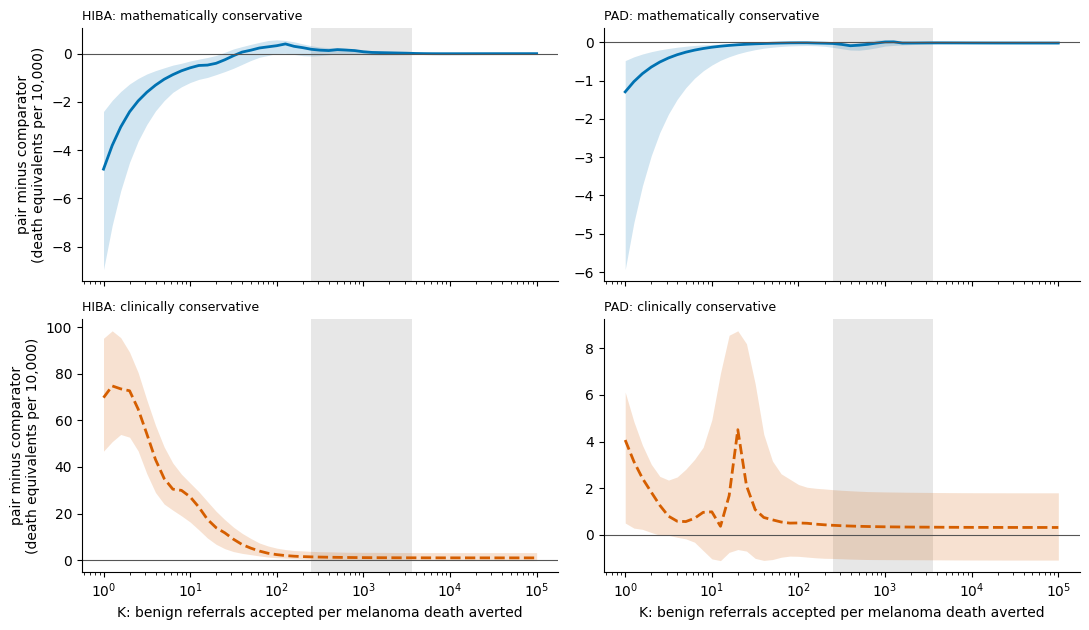

In [6]:
def breakeven(adv):
    if adv[-1] <= 0: return np.inf
    neg = np.where(adv <= 0)[0]
    if len(neg) == 0: return -np.inf
    i = neg[-1]; a0, a1 = adv[i], adv[i + 1]; t = -a0 / (a1 - a0)
    return float(np.exp(np.log(KS[i]) + t * (np.log(KS[i + 1]) - np.log(KS[i]))))
def fmt(k): return f"below {KS[0]:.0f}" if k < KS[0] else (f"above {KS[-1]:,.0f}" if k > KS[-1] else f"{k:,.0f}")
def pct(bs, q): return float(np.percentile(np.clip(bs, KS[0] / 2, KS[-1] * 2), q))
be, curve_rows = [], []
for name, r in RES.items():
    for c in CMP:
        for h, lab in HARMS.items():
            tk = r[c]["tuned_k"][h]; pt = tk[0]; bs = np.array([breakeven(tk[b]) for b in range(1, B + 1)])
            be.append({"population": name, "comparator": c, "harm": lab, "breakeven_K": fmt(breakeven(pt)), "ci": f"{fmt(pct(bs, 2.5))} to {fmt(pct(bs, 97.5))}",
                       "point_value": breakeven(pt), "share_resamples_never_ahead": float((bs == np.inf).mean())})
            lo, hi = np.percentile(tk[1:], 2.5, 0), np.percentile(tk[1:], 97.5, 0)
            for i, K in enumerate(KS): curve_rows.append({"population": name, "comparator": c, "harm": lab, "K": K, "advantage": pt[i], "ci_lo": lo[i], "ci_hi": hi[i]})
BE = pd.DataFrame(be); BE.to_csv(f"{OUTD}/derm_B_breakeven_K_v4.csv", index=False); CUR = pd.DataFrame(curve_rows); CUR.to_csv(f"{OUTD}/derm_B_tuned_K_v4.csv", index=False)
BE["cell"] = BE.breakeven_K + " (" + BE.ci + ")"
display(BE.pivot_table(index="harm", columns=["population", "comparator"], values="cell", aggfunc="first"))
BOUNDS = {"mathematically conservative": ("better", "lit_central", "#0072B2", "-"), "clinically conservative": ("deployed", "worst", "#D55E00", "--")}
fig, ax = plt.subplots(2, len(RES), figsize=(11, 6.4), sharex=True)
for j, (name, r) in enumerate(RES.items()):
    for row, (lab, (c, h, col, ls)) in enumerate(BOUNDS.items()):
        x = ax[row][j]; tk = r[c]["tuned_k"][h]
        x.axvspan(*NNB_BAND, color="#BDBDBD", alpha=0.35, lw=0)
        x.fill_between(KS, np.percentile(tk[1:], 2.5, 0), np.percentile(tk[1:], 97.5, 0), color=col, alpha=0.18, lw=0); x.plot(KS, tk[0], color=col, lw=2, ls=ls)
        x.axhline(0, color="#555555", lw=0.8); x.set_xscale("log"); x.set_title(f"{name}: {lab}", loc="left", fontsize=9)
        [x.spines[s].set_visible(False) for s in ("top", "right")]
        if row == 1: x.set_xlabel("K: benign referrals accepted per melanoma death averted")
        if j == 0: x.set_ylabel("pair minus comparator\n(death equivalents per 10,000)")
fig.tight_layout(); fig.savefig(f"{OUTD}/derm_bounds_tuned_vs_K_v4.png", dpi=200); plt.show()

## 6. D. Union at each system's own threshold
Referring any lesion either system flags, against the comparator alone. This is the rule most favourable to pairing: the union cannot miss a lesion that either member refers, so the only question is what the extra referrals cost.

**Which member is "better".** In each resample the better member is chosen on the outcome the row reports, as in sections 4 and 5:
- per extra melanoma: the member that missed fewer melanomas;
- per death averted, average case: the member with fewer expected deaths among its misses (melanoma 1/85, SCC 0.006, BCC 0);
- per death averted, worst case: the same with melanoma counted as 1.

For comparison the v3 definition (better member always chosen on melanoma) is also reported for the per-death rows. The deployed comparator does not depend on this choice.

Each ratio is computed in every resample from the pair-averaged numerator and denominator, the same way as the point estimate. A resample in which the union averted nothing has an infinite ratio; the share of such resamples is reported.

In [7]:
def ratio_ci(num, den):
    r = np.where(den > 0, num / np.where(den > 0, den, 1), np.inf)
    return float(r[0]), float(np.percentile(r[1:], 2.5)), float(np.percentile(r[1:], 97.5)), float(np.mean(~np.isfinite(r[1:])))
ROWS_D = [("per extra melanoma", "melanomas", "union_fp", "union_mel"),
          ("per death averted, average case", "outcome", "union_fp_lit_own", "union_lit_own"),
          ("per death averted, worst case", "outcome", "union_fp_worst_own", "union_worst_own"),
          ("per death averted, average case", "melanomas (v3)", "union_fp", "union_lit"),
          ("per death averted, worst case", "melanomas (v3)", "union_fp", "union_worst")]
rows = []
for name, r in RES.items():
    for c in CMP:
        for meas, chosen, kf, kg in ROWS_D:
            if c == "deployed" and chosen == "melanomas (v3)": continue
            row = {"population": name, "comparator": c, "measure": meas, "better_chosen_on": chosen if c == "better" else "not applicable"}
            row["extra_benign"], row["extra_benign_lo"], row["extra_benign_hi"] = ci(r[c][kf])
            row["averted"], row["averted_lo"], row["averted_hi"] = ci(r[c][kg])
            row["cost"], row["cost_lo"], row["cost_hi"], row["share_infinite"] = ratio_ci(r[c][kf], r[c][kg])
            rows.append(row)
U = pd.DataFrame(rows); U.to_csv(f"{OUTD}/derm_D_union_v4.csv", index=False)
for _, x in U.iterrows():
    print(f"{x.population:5s} {x.comparator:8s} {x.measure:32s} better on {x.better_chosen_on:16s} extra benign {x.extra_benign:7.1f}  averted {x.averted:7.3f}  cost {x.cost:7.1f} ({x.cost_lo:.1f} to {x.cost_hi:.1f})  inf {x.share_infinite:.3f}")

HIBA  better   per extra melanoma               better on melanomas        extra benign   701.3  averted 103.253  cost     6.8 (5.2 to 9.7)  inf 0.000
HIBA  better   per death averted, average case  better on outcome          extra benign   709.8  averted   1.620  cost   438.1 (339.3 to 589.7)  inf 0.000
HIBA  better   per death averted, worst case    better on outcome          extra benign   701.4  averted 103.674  cost     6.8 (5.2 to 9.6)  inf 0.000
HIBA  better   per death averted, average case  better on melanomas (v3)   extra benign   701.3  averted   1.638  cost   428.1 (333.1 to 572.9)  inf 0.000
HIBA  better   per death averted, worst case    better on melanomas (v3)   extra benign   701.3  averted 103.676  cost     6.8 (5.2 to 9.6)  inf 0.000
HIBA  deployed per extra melanoma               better on not applicable   extra benign   667.9  averted 125.028  cost     5.3 (4.0 to 7.1)  inf 0.000
HIBA  deployed per death averted, average case  better on not applicable   extra benig

## 7. Referral sets at the locked share (for sections 8 to 10)

In [8]:
SETS = {}
for name, d in POP.items():
    n = len(d["dx"]); R = {m: rankdata(p) / n for m, p in d["P"].items()}; k = int(round(d["f"] * n))
    def top(score): o = np.argsort(-score, kind="stable"); s = np.zeros(n, bool); s[o[:k]] = True; return s
    single = {m: top(R[m]) for m in MODELS}
    pair = {((*va, i), (*vb, j)): top(np.maximum(R[(*va, i)], R[(*vb, j)]) + 1e-9 * np.minimum(R[(*va, i)], R[(*vb, j)])) for va, vb in PAIRS for i in SEEDS for j in SEEDS}
    SETS[name] = {"single": single, "pair": pair, "k": k}
    print(f"{name}: {k:,} of {n:,} referred; {len(single)} single sets, {len(pair)} pair sets")

HIBA: 984 of 1,616 referred; 24 single sets, 264 pair sets
PAD: 1,416 of 2,283 referred; 24 single sets, 264 pair sets


## 8. Operating characteristics

In [9]:
def opchars(ref, dx):
    pos = np.isin(dx, ["MEL", "BCC", "SCC"]); mel = dx == "MEL"
    tp = (ref & pos).sum(); fp = (ref & ~pos).sum(); fn = (~ref & pos).sum(); tn = (~ref & ~pos).sum()
    return {"sensitivity_any_cancer": tp / (tp + fn), "sensitivity_melanoma": (ref & mel).sum() / mel.sum(), "specificity": tn / (tn + fp),
            "PPV": tp / (tp + fp), "NPV": tn / (tn + fn), "referral_rate": ref.mean()}
rows = []
for name, d in POP.items():
    for kind in ("single", "pair"):
        df = pd.DataFrame([opchars(s, d["dx"]) for s in SETS[name][kind].values()])
        for col in df.columns:
            rows.append({"population": name, "reader": "single system (24)" if kind == "single" else "pair (264)", "measure": col, "mean": df[col].mean(), "min": df[col].min(), "max": df[col].max()})
OC = pd.DataFrame(rows); OC.to_csv(f"{OUTD}/derm_opchars_v4.csv", index=False)
OC["cell"] = OC.apply(lambda x: f"{100 * x['mean']:.1f}% ({100 * x['min']:.1f} to {100 * x['max']:.1f})", axis=1)
display(OC.pivot_table(index=["population", "measure"], columns="reader", values="cell", aggfunc="first"))

reader                                       pair (264)    single system (24)
population measure                                                           
HIBA       NPV                     90.6% (87.0 to 93.7)  88.7% (85.1 to 92.1)
           PPV                     70.3% (68.0 to 72.3)  69.1% (66.8 to 71.2)
           referral_rate           60.9% (60.9 to 60.9)  60.9% (60.9 to 60.9)
           sensitivity_any_cancer  92.1% (89.1 to 94.7)  90.5% (87.5 to 93.3)
           sensitivity_melanoma    86.5% (80.6 to 91.7)  85.5% (79.8 to 89.7)
           specificity             66.2% (63.6 to 68.4)  64.8% (62.2 to 67.3)
PAD        NPV                     75.5% (68.1 to 83.0)  72.7% (65.7 to 81.2)
           PPV                     61.3% (56.8 to 66.0)  59.7% (55.4 to 64.8)
           referral_rate           62.0% (62.0 to 62.0)  62.0% (62.0 to 62.0)
           sensitivity_any_cancer  80.3% (74.4 to 86.4)  78.1% (72.5 to 84.9)
           sensitivity_melanoma    52.1% (32.7 to 69.2)  49.9% (34.6 to 61.5)
           specificity             54.4% (49.1 to 59.9)  52.5% (47.4 to 58.6)

## 9. Case influence: HIBA melanoma against the deployed system
The statistic is the mean over the 264 combinations of the deployed system's missed melanomas (the average of the two members) minus the pair's. Each melanoma's contribution is its share of that average. Melanomas are removed in order of contribution, ranks and referral sets are recomputed from scratch, and the statistic is recalculated. The same is done for the better-member comparator.

In [10]:
def stat(d, keep, how):
    dx = d["dx"][keep]; n = len(dx); k = int(round(d["f"] * n)); mel = dx == "MEL"
    R = {m: rankdata(p[keep]) / n for m, p in d["P"].items()}
    def top(score): o = np.argsort(-score, kind="stable"); s = np.zeros(n, bool); s[o[:k]] = True; return s
    ms = {m: (~top(R[m]) & mel).sum() for m in MODELS}; vals = []
    for va, vb in PAIRS:
        for i in SEEDS:
            for j in SEEDS:
                ma, mb = (*va, i), (*vb, j); ps = top(np.maximum(R[ma], R[mb]) + 1e-9 * np.minimum(R[ma], R[mb]))
                base_ = 0.5 * (ms[ma] + ms[mb]) if how == "deployed" else min(ms[ma], ms[mb]); vals.append(base_ - (~ps & mel).sum())
    return float(np.mean(vals))
d = POP["HIBA"]; dx = d["dx"]; S = SETS["HIBA"]; mel = dx == "MEL"; mel_idx = np.where(mel)[0]; INFL = {}
for how in ("deployed", "better"):
    contrib = np.zeros(len(dx)); miss_s = {m: ~S["single"][m] & mel for m in MODELS}
    for (ma, mb), ps in S["pair"].items():
        if how == "deployed": contrib += 0.5 * (miss_s[ma].astype(float) + miss_s[mb].astype(float)) - (~ps & mel).astype(float)
        else:
            bt = ma if miss_s[ma].sum() <= miss_s[mb].sum() else mb; contrib += miss_s[bt].astype(float) - (~ps & mel).astype(float)
    contrib /= len(S["pair"]); base = stat(d, np.ones(len(dx), bool), how)
    order = mel_idx[np.argsort(-contrib[mel_idx])]; curve = [{"removed": 0, "net_melanomas_avoided": base}]; zero_at = None
    for k in range(1, 31):
        keep = np.ones(len(dx), bool); keep[order[:k]] = False; v = stat(d, keep, how); curve.append({"removed": k, "net_melanomas_avoided": v})
        if zero_at is None and v <= 0: zero_at = k
    rng = np.random.default_rng(20261030); rand = {}
    for k in (5, 10, 20):
        v = [stat(d, np.isin(np.arange(len(dx)), rng.choice(mel_idx, k, replace=False), invert=True), how) for _ in range(20)]
        rand[k] = (float(np.mean(v)), float(np.min(v)), float(np.max(v)))
    INFL[how] = {"all_lesions": base, "sum_of_contributions": float(contrib.sum()), "curve": curve, "influential_to_reach_zero": zero_at, "random_removal": rand, "melanomas": int(mel.sum())}
    print(f"HIBA melanoma vs {how}: {base:.3f} net melanomas avoided per pair (sum of contributions {contrib.sum():.3f})")
    print(pd.DataFrame(curve).iloc[[0, 1, 2, 3, 5, 10, 15, 20, 25, 30]].round(3).to_string(index=False))
    print(f"  most influential melanomas removed before zero: {zero_at if zero_at else 'more than 30'} of {mel.sum()}; random removal (20 draws):",
          {k: f"{v[0]:.3f} ({v[1]:.3f} to {v[2]:.3f})" for k, v in rand.items()})
pd.DataFrame([{**c, "comparator": h} for h, v in INFL.items() for c in v["curve"]]).to_csv(f"{OUTD}/derm_case_influence_v4.csv", index=False)

HIBA melanoma vs deployed: 2.458 net melanomas avoided per pair (sum of contributions 2.458)
 removed  net_melanomas_avoided
       0                  2.458
       1                  2.254
       2                  2.148
       3                  2.004
       5                  1.792
      10                  1.227
      15                  0.848
      20                  0.405
      25                  0.083
      30                 -0.273
  most influential melanomas removed before zero: 27 of 253; random removal (20 draws): {5: '2.599 (2.428 to 2.773)', 10: '2.536 (2.083 to 2.924)', 20: '2.569 (2.061 to 3.008)'}
HIBA melanoma vs better: -1.061 net melanomas avoided per pair (sum of contributions -1.061)
 removed  net_melanomas_avoided
       0                 -1.061
       1                 -1.280
       2                 -1.447
       3                 -1.629
       5                 -1.818
      10                 -2.511
      15                 -2.905
      20                 -3.

## 10. CNN against transformer
Per pair, at the locked share:
- **Benefit:** net melanomas, and net cancers, missed less than the better member, per 10,000 lesions.
- **Shared-miss ratio** for melanoma and for any cancer.

Groups are CNN with CNN, CNN with transformer, and transformer with transformer. Each is shown:
- for all pairs;
- for pairs trained on different collections only;
- for pairs excluding the same backbone family (the two ViT-B systems count as one family).

Intervals come from 1,000 patient resamples with referral sets held fixed.

In [11]:
GROUPS = {"CNN with CNN": ("CNN", "CNN"), "CNN with transformer": ("CNN", "transformer"), "transformer with transformer": ("transformer", "transformer")}
rows = []
for name, d in POP.items():
    dx = d["dx"]; S = SETS[name]; n = len(dx); codes = pd.factorize(d["group"])[0]; G = codes.max() + 1; rng = np.random.default_rng(SEED)
    W = np.vstack([np.ones(n)] + [np.bincount(rng.integers(0, G, G), minlength=G)[codes] for _ in range(B)]).astype(np.float32)
    for oname, y in (("melanoma", dx == "MEL"), ("any cancer", np.isin(dx, ["MEL", "BCC", "SCC"]))):
        ms = {m: W @ (~S["single"][m] & y).astype(np.float32) for m in MODELS}; ny = W @ y.astype(np.float32); per = {}
        for (ma, mb), ps in S["pair"].items():
            grp = next(g for g, kk in GROUPS.items() if sorted((KIND[ma[1]], KIND[mb[1]])) == sorted(kk))
            subs = ["all pairs"] + (["different collections only"] if ma[0] != mb[0] else []) + (["excluding same family"] if FAMILY[ma[1]] != FAMILY[mb[1]] else [])
            pm = W @ (~ps & y).astype(np.float32); both = W @ ((~S["single"][ma]) & (~S["single"][mb]) & y).astype(np.float32)
            ben = (np.minimum(ms[ma], ms[mb]) - pm) / W.sum(1) * 1e4; rat = (both / ny) / ((ms[ma] / ny) * (ms[mb] / ny) + 1e-12)
            for sub in subs: per.setdefault((grp, sub), {"benefit": [], "ratio": []}); per[(grp, sub)]["benefit"].append(ben); per[(grp, sub)]["ratio"].append(rat)
        for (grp, sub), v in per.items():
            for meas in ("benefit", "ratio"):
                x = np.mean(np.stack(v[meas]), 0)
                rows.append({"population": name, "outcome": oname, "group": grp, "subset": sub, "measure": "net misses avoided per 10,000 vs better member" if meas == "benefit" else "shared-miss ratio",
                             "combinations": len(v[meas]), "estimate": float(x[0]), "ci_lo": float(np.percentile(x[1:], 2.5)), "ci_hi": float(np.percentile(x[1:], 97.5))})
CT = pd.DataFrame(rows); CT.to_csv(f"{OUTD}/derm_cnn_transformer_v4.csv", index=False)
CT["cell"] = CT.apply(lambda x: f"{x.estimate:.2f} ({x.ci_lo:.2f} to {x.ci_hi:.2f}); n={x.combinations}", axis=1)
for (o, meas), t in CT.groupby(["outcome", "measure"]):
    print(f"\n=== {o}: {meas} ==="); display(t.pivot_table(index=["group", "subset"], columns="population", values="cell", aggfunc="first"))


=== any cancer: net misses avoided per 10,000 vs better member ===


population                                                                         HIBA                             PAD
group                        subset                                                                                    
CNN with CNN                 all pairs                     39.28 (8.17 to 57.87); n=112    45.84 (5.80 to 74.05); n=112
                             different collections only    57.72 (19.31 to 81.22); n=64     56.94 (4.03 to 94.10); n=64
                             excluding same family          37.06 (6.83 to 55.19); n=96     42.52 (3.50 to 71.27); n=96
CNN with transformer         all pairs                   18.03 (-13.22 to 39.36); n=128  12.94 (-24.07 to 39.13); n=128
                             different collections only   24.46 (-10.30 to 49.31); n=64    7.12 (-40.77 to 46.04); n=64
                             excluding same family       18.03 (-13.22 to 39.36); n=128  12.94 (-24.07 to 39.13); n=128
transformer with transformer all pairs                    13.92 (-28.05 to 38.70); n=24  -43.62 (-101.47 to 5.28); n=24
                             different collections only   20.11 (-25.65 to 49.11); n=16  -49.82 (-119.85 to 7.29); n=16


=== any cancer: shared-miss ratio ===


population                                                                     HIBA                         PAD
group                        subset                                                                            
CNN with CNN                 all pairs                   3.35 (2.98 to 3.78); n=112  1.78 (1.70 to 1.88); n=112
                             different collections only   2.96 (2.54 to 3.41); n=64   1.55 (1.45 to 1.66); n=64
                             excluding same family        3.38 (3.01 to 3.82); n=96   1.82 (1.73 to 1.91); n=96
CNN with transformer         all pairs                   3.79 (3.38 to 4.29); n=128  1.71 (1.62 to 1.80); n=128
                             different collections only   3.39 (2.93 to 3.94); n=64   1.52 (1.43 to 1.62); n=64
                             excluding same family       3.79 (3.38 to 4.29); n=128  1.71 (1.62 to 1.80); n=128
transformer with transformer all pairs                    4.48 (3.79 to 5.37); n=24   1.71 (1.60 to 1.83); n=24
                             different collections only   4.11 (3.38 to 5.07); n=16   1.54 (1.42 to 1.68); n=16


=== melanoma: net misses avoided per 10,000 vs better member ===


population                                                                        HIBA                             PAD
group                        subset                                                                                   
CNN with CNN                 all pairs                   -7.96 (-28.30 to 3.23); n=112  -7.63 (-18.80 to -1.83); n=112
                             different collections only   -4.45 (-27.15 to 8.01); n=64  -10.81 (-23.69 to -1.88); n=64
                             excluding same family        -8.32 (-29.22 to 2.94); n=96   -6.98 (-18.08 to -1.39); n=96
CNN with transformer         all pairs                   -5.51 (-24.83 to 3.22); n=128   -5.54 (-17.07 to 0.51); n=128
                             different collections only   -3.96 (-25.14 to 5.14); n=64    -8.69 (-21.46 to 0.21); n=64
                             excluding same family       -5.51 (-24.83 to 3.22); n=128   -5.54 (-17.07 to 0.51); n=128
transformer with transformer all pairs                   -5.67 (-36.69 to 11.12); n=24    -5.84 (-18.09 to 2.17); n=24
                             different collections only  -11.60 (-46.13 to 8.51); n=16    -7.94 (-21.61 to 2.51); n=16


=== melanoma: shared-miss ratio ===


population                                                                     HIBA                         PAD
group                        subset                                                                            
CNN with CNN                 all pairs                   3.13 (2.62 to 3.70); n=112  1.30 (1.15 to 1.55); n=112
                             different collections only   2.93 (2.42 to 3.52); n=64   1.24 (1.09 to 1.45); n=64
                             excluding same family        3.13 (2.61 to 3.70); n=96   1.31 (1.16 to 1.56); n=96
CNN with transformer         all pairs                   3.20 (2.72 to 3.75); n=128  1.30 (1.15 to 1.52); n=128
                             different collections only   3.01 (2.52 to 3.59); n=64   1.22 (1.06 to 1.43); n=64
                             excluding same family       3.20 (2.72 to 3.75); n=128  1.30 (1.15 to 1.52); n=128
transformer with transformer all pairs                    3.37 (2.77 to 4.08); n=24   1.39 (1.20 to 1.70); n=24
                             different collections only   3.26 (2.61 to 4.00); n=16   1.35 (1.15 to 1.66); n=16

## 11. Write the results record

In [12]:
def tolist(x): return {k: tolist(v) for k, v in x.items()} if isinstance(x, dict) else (x.tolist() if isinstance(x, np.ndarray) else x)
REC = {"status": "secondary, post hoc; not specified in a dated lock; mirrors retina notebooks 18, 18b and 19", "written_utc": datetime.datetime.now(datetime.timezone.utc).isoformat(),
       "systems": "24 skin systems (2 collections x 6 designs x 2 seeds); 66 variant pairs x 4 seed combinations", "bootstrap": {"resamples": B, "seed": SEED, "unit": "patients", "conditional_on": "full-sample rank transforms"},
       "harm_model": {"melanoma_deaths_per_miss_average_case": MEL, "scc_deaths_per_miss": SCC_DEATH, "bcc": 0, "worst_case": "each missed melanoma is one death; SCC at its average value",
                      "sources": "Gilmore 2017 PLoS ONE (50 to 120 early invasive melanoma excisions per life saved); Tokez et al. 2022 JAAD (cSCC 5-year disease-specific mortality about 0.6%)"},
       "pricing": {"K": "benign referrals per melanoma death averted", "grid": [float(KS[0]), float(KS[-1]), len(KS)], "reference_band": NNB_BAND, "band_basis": "number needed to biopsy 5 to 30 (Petty et al. 2020 JAAD; Nelson et al. 2019 JAMA Dermatol) x 50 to 120 melanomas per death averted"},
       "populations": {n: {"lesions": r["n"], "patients": r["patients"], "f": r["f"]} for n, r in RES.items()},
       "A_matched_volume": A.drop(columns="cell").to_dict("records"), "B_breakeven_K": BE.drop(columns="cell").to_dict("records"), "D_union": U.to_dict("records"),
       "operating_characteristics": OC.drop(columns="cell").to_dict("records"), "case_influence_HIBA_melanoma": INFL, "cnn_vs_transformer": CT.drop(columns="cell").to_dict("records"), "input_sha256": HASHES}
with open(OUT_JSON, "w") as fh: json.dump(tolist(REC), fh, indent=1, default=float)
drive.flush_and_unmount(); drive.mount("/content/drive")
print("written", OUT_JSON, "and CSVs and the figure in", OUTD)

Mounted at /content/drive
written /content/drive/MyDrive/stochastic_orthogonality/data/derm/secondary_v4/derm_secondary_v4.json and CSVs and the figure in /content/drive/MyDrive/stochastic_orthogonality/data/derm/secondary_v4
